# KAN-5 — Features do modelo de aplicação

Projeto CIN0144 · Tema 8: Praso — Previsão de Inadimplência.

Objetivo: transformar a tabela de clientes nas features do **modelo de aplicação**, o que estima o risco de um cliente no momento do cadastro, e justificar cada escolha com a EDA (notebook 02).

**Regras**
- Só a tabela de clientes. Nada vem dos pedidos, nem uma flag "tem pedidos": no cadastro o cliente ainda não comprou.
- O que não aprende nada dos dados fica em `src/features_aplicacao.py` (`criar_features`) e pode rodar na base inteira.
- O que aprende dos dados (agrupar categorias raras, *target encoding*) fica no pré-processador, ajustado **só no treino** dentro do `Pipeline`.
- Toda escolha que olha o alvo usa só o treino.
- Saídas só com agregados, nunca linhas de clientes (o repositório é público).

**Roteiro**

| Seção | Conteúdo | Status |
|---|---|---|
| 1 | Configuração e carregamento | feito |
| 2 | Split treino/teste (80/20) e validação cruzada 5×5 | feito |
| 3 | Pendências de qualidade herdadas da KAN-1 e da EDA | feito |
| 4 | Features determinísticas | feito |
| 5 | Pré-processador (ajustado no treino) e escolha dos modelos de árvore | feito |
| 6 | Validação das features (ablação no treino) e verificações finais (6.3) | feito |
| 7 | Checagens de vazamento | feito |
| 8 | Resumo | feito |

## 1. Configuração

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src import dados
from src import features_aplicacao as fa
from src import split as sp

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

In [2]:
clientes, pedidos = dados.carregar_dados_limpos()  # pedidos só para estratificar o split (seção 2), nunca como feature
print(f"clientes: {clientes.shape} | taxa de inadimplência: {clientes['inadimplente'].mean():.1%}")

clientes: (3000, 19) | taxa de inadimplência: 31.3%


## 2. Split treino/teste e validação cruzada

**80/20**, estratificado por `inadimplente × tem_pedidos` (`src/split.py`, seed 42). A divisão é aleatória dentro de cada estrato: o alvo só fixa a proporção de inadimplentes em cada conjunto, nunca quais clientes vão para cada um.

| Conjunto | Papel |
|---|---|
| treino (80%) | ajustar o pré-processador e os modelos. **Validação cruzada estratificada repetida, 5 folds × 5 repetições**, para escolher features e modelo, calibrar e tirar as predições fora da amostra usadas nos cortes da política de crédito (KAN-9) |
| teste (20%) | avaliação final, uma vez só por modelo escolhido |

A estratificação por "tem pedidos" deixa os 664 clientes com pedidos na mesma proporção no treino e no teste, para a KAN-8 comparar os dois modelos nos mesmos clientes. A informação não entra no modelo de aplicação.

O split fica salvo em `data/processed/split.csv` (fora do git). A KAN-6 e a KAN-8 leem com `sp.carregar_split()` e geram os mesmos folds com `sp.folds(treino, pedidos)`.

In [3]:
split = sp.criar_split(clientes, pedidos)
sp.salvar_split(split)
conjunto = clientes["id_cliente"].map(split)

tem_pedidos = clientes["id_cliente"].isin(pedidos["id_cliente"])
resumo = pd.DataFrame({
    "n": conjunto.value_counts(),
    "% da base": conjunto.value_counts(normalize=True),
    "taxa de inadimplência": clientes.groupby(conjunto)["inadimplente"].mean(),
    "% com pedidos": tem_pedidos.groupby(conjunto).mean(),
    "inadimplentes com pedidos": (tem_pedidos & clientes["inadimplente"].eq(1)).groupby(conjunto).sum(),
}).loc[["treino", "teste"]]
assert conjunto.notna().all() and resumo["n"].sum() == len(clientes)
assert (sp.carregar_split().reindex(clientes["id_cliente"]).to_numpy() == conjunto.to_numpy()).all()
resumo

,n,% da base,taxa de inadimplência,% com pedidos,inadimplentes com pedidos
id_cliente,,,,,
treino,2400,0.800,0.313,0.221,110
teste,600,0.200,0.313,0.222,28


In [4]:
treino = clientes[conjunto == "treino"].reset_index(drop=True)
cv = sp.folds(treino, pedidos)

# Cada fold de validação deve ter ~1/5 do treino e a mesma taxa de inadimplência
tam = pd.Series([len(v) for _, v in cv])
taxa = pd.Series([treino["inadimplente"].iloc[v].mean() for _, v in cv])
print(f"{len(cv)} folds | clientes por fold de validação: {tam.min()} a {tam.max()} "
      f"| taxa de inadimplência por fold: {taxa.min():.1%} a {taxa.max():.1%}")

25 folds | clientes por fold de validação: 480 a 480 | taxa de inadimplência por fold: 31.2% a 31.5%


**Leitura:**

A estratificação funcionou. Treino (2.400) e teste (600) têm a mesma taxa de inadimplência (31,3%) e a mesma fração com pedidos (22%), e os 25 folds têm 480 clientes cada, com taxa entre 31,2% e 31,5%. Com 600 clientes, o teste tem ~190 inadimplentes, e o erro padrão do AUC fica perto de 0,022: diferenças menores que isso entre modelos não devem ser lidas como ganho.

**Alerta para a KAN-8:**

No teste, só 28 inadimplentes têm pedidos. Um AUC calculado nos clientes com pedidos do teste tem erro padrão perto de 0,05, então a comparação entre o modelo de aplicação e o comportamental precisa de intervalo de confiança (bootstrap).

A partir daqui, **toda escolha que olha o alvo usa só o treino**.

## 3. Pendências de qualidade

Questões que a limpeza (notebook 01) e a EDA (notebook 02) deixaram para a engenharia de features. Só contagens.

### 3.1 `google_maps_tem_website` × presença no Maps

O website só vale 1 ou nulo, e o nulo pode ser "não está no Maps" ou "está, mas sem site". Cruzando com `google_maps_contagem_avaliacoes`, que indica presença no Maps:
- se só a diagonal tiver valores, a coluna repete `tem_gmaps` e sai do modelo;
- se houver "com contagem, website nulo", dá para separar "está no Maps sem site".

In [5]:
no_maps = clientes["google_maps_contagem_avaliacoes"].notna().map({True: "com contagem", False: "sem contagem"})
site = clientes["google_maps_tem_website"].notna().map({True: "website = 1", False: "website nulo"})
pd.crosstab(no_maps, site)

google_maps_tem_website,website = 1,website nulo
google_maps_contagem_avaliacoes,,
com contagem,208,0
sem contagem,0,2792


**Resposta:** 

Só a diagonal tem valores. O website é nulo exatamente nos 2.792 clientes que não estão no Maps e vale 1 em todos os 208 que estão. A coluna é uma cópia de `tem_gmaps`, e não há como separar "está no Maps sem site".

**Decisão:**

`google_maps_tem_website` sai do modelo.

### 3.2 Repetições na lista de credores

`n_credores` conta os itens de `serasa_credores`. Se um segmento aparece duas vezes na mesma lista, conta dois credores. Quantos clientes têm segmento repetido, e quantos passam de 5 itens (a Praso diz "até 5")?

In [6]:
credores = fa.lista_credores(clientes["serasa_credores"])
n_itens, n_unicos = credores.str.len(), credores.map(lambda l: len(set(l)))
pd.Series({
    "clientes com credores listados": int((n_itens > 0).sum()),
    "com algum segmento repetido na lista": int((n_itens > n_unicos).sum()),
    "com mais de 5 itens": int((n_itens > 5).sum()),
    "com mais de 5 segmentos distintos": int((n_unicos > 5).sum()),
}, name="clientes").to_frame()

,clientes
clientes com credores listados,534
com algum segmento repetido na lista,84
com mais de 5 itens,5
com mais de 5 segmentos distintos,1


**Resposta:**

84 dos 534 clientes com credores (16%) têm algum segmento repetido na lista. 5 têm mais de 5 itens, mas só 1 tem mais de 5 segmentos distintos.

**Decisão:**

`n_credores` conta os **itens** da lista. A lista só mostra o segmento, então dois credores diferentes do mesmo setor (dois bancos, por exemplo) aparecem repetidos: a repetição é esperada, não erro. É também a contagem da EDA, então o gradiente de 28% a 72% (seção 4.3) continua valendo. Os 5 clientes com mais de 5 itens não recebem tratamento especial: os modelos de árvore só usam a ordem dos valores, então valores altos não distorcem nada.

### 3.3 Negativados sem credor listado

97 clientes têm negativação e nenhum credor listado (EDA, seção 8). Para eles, `serasa_credores` nulo pode ser informação faltando, e não "sem credores". Em vez de imputar, a feature `negativado_sem_credor` marca esses casos e deixa o modelo decidir (seção 4).

### 3.4 Segmentos de credor

Quais segmentos aparecem em `serasa_credores`, e em quantos clientes? 

A contagem não olha o alvo: serve para classificar cada segmento pelo **significado** (fornecedor de mercadoria, financeiro, serviços) antes de criar as flags por tipo de credor.

In [7]:
pd.DataFrame({
    "clientes": credores.map(set).explode().dropna().value_counts(),
    "itens na base": credores.explode().dropna().value_counts(),
}).rename_axis("segmento do credor")

,clientes,itens na base
segmento do credor,,
Alimentos e Bebidas,165,210
Atacadista,4,4
Bancos e Financeiro,164,198
Comunicação,5,5
Comunicação e Mídia,1,1
Comércio,24,25
Consultoria,4,4
Contabilidade,1,1
Distribuição,75,88


**Resposta:** 

São 30 segmentos. Sete concentram quase tudo (de 42 a 165 clientes), e os outros 23 têm de 1 a 28. Há nomes quase iguais ("Comunicação" e "Comunicação e Mídia"; "Financeiro", "Bancos e Financeiro" e "Seguros e Financeiro"), o que reforça agrupar pelo significado.

**Decisão:** 

Cada segmento vai para um de três tipos de credor (`fa.GRUPO_CREDOR`), e cada tipo vira uma flag `deve_<tipo>`. Um cliente pode ter mais de uma.

| Tipo | Segmentos | Lógica |
|---|---|---|
| `mercadoria` | Alimentos e Bebidas, Distribuição, Comércio, Indústria, Tabaco, Representação Comercial, Atacadista | quem vende produto ao varejista, o mesmo tipo de credor que a Praso |
| `financeiro` | Bancos e Financeiro, Tecnologia e Pagamentos, Financeiro, Seguros e Financeiro | dívida de crédito; "Tecnologia e Pagamentos" entra aqui por maquininha e antecipação de recebíveis |
| `servicos` | Saúde, Telecomunicações, Tecnologia, Energia, Comunicação, Logística, Serviços, Consultoria, Segurança, Imobiliário, Limpeza e os 6 segmentos com 1 cliente | custo de operação do negócio |
| sem tipo | Diversos, Governo | sem significado claro, ou de natureza diferente (provável tributo): não recebem flag, mas continuam contando em `tem_credores` e `n_credores` |

A classificação usa só o nome do segmento, não o alvo. Na EDA (4.3), os credores de mercadoria e financeiros foram os de maior risco (58% a 65%), e os de serviços ficaram entre 40% e 43%; a ablação (seção 6) confere no treino se as flags acrescentam algo ao número de credores.

## 4. Features determinísticas

Calculadas por `fa.criar_features(clientes)`.

> **Esta seção roda na base inteira (3.000 clientes), inclusive no teste.** Isso é seguro porque cada feature é calculada só com a linha do próprio cliente: o resultado de um cliente não muda se os outros clientes mudarem (a seção 7 confere isso). Nenhuma feature olha o alvo nem conta clientes. Exemplos: `"$$$"` → 3, lista de credores → `n_credores`, município → região por uma lista fixa. O que depende de contagens ou médias do conjunto de clientes fica para o pré-processador (seção 5), ajustado só no treino.

| Feature | Origem | Como | Por quê (EDA) |
|---|---|---|---|
| `idade_cnpj_ord` | `idade_cnpj` | posição da faixa (0 = mais nova) | variável mais forte, de 57% a 6% (4.1) |
| `capital_social_ord` | `capital_social` | posição da faixa | tendência fraca, mas presente (4.2) |
| `negativacoes`, `protestos` | Serasa | contagem como veio (árvores só usam a ordem dos valores, então a cauda longa não atrapalha) | cauda longa, valores altos plausíveis (3.3) |
| `n_credores` | `serasa_credores` | nº de itens da lista | gradiente mais forte da Serasa, de 28% a 72% (4.3) |
| `socio_negativado` | Serasa | como veio | 42% contra 22% (4.3) |
| `tem_credores` | `serasa_credores` | lista não vazia | 48,5% contra 27,6% (4.4) |
| `sem_registro_serasa` | Serasa | 0 negativações, 0 credores e sócio sem negativação | grupo "limpo" da EDA (1.431 clientes, 21,3%, seção 6.4), sem os negativados que vieram sem credor listado |
| `negativado_sem_credor` | Serasa | negativação > 0 e 0 credores | os 97 casos em que o nulo pode ser falta de informação (8) |
| `deve_mercadoria`, `deve_financeiro`, `deve_servicos` | `serasa_credores` | deve a pelo menos um credor do tipo (seção 3.4) | o tipo de credor importa além da quantidade (4.3) |
| `tem_ifood` | iFood | tem faixa de preço **ou** contagem | 177 clientes têm só a faixa (notebook 01) |
| `tem_gmaps` | Google Maps | tem contagem de avaliações | sinal fraco, mas barato (4.4) |
| `ifood_preco_ord` | `ifood_faixa_preco` | nº de `$` (0 = não está) | ordinal |
| `ifood_avaliacoes_ord`, `gmaps_avaliacoes_ord` | contagens | posição da faixa (−1 = sem contagem) | 0 de 40 inadimplentes acima de 750 avaliações no Maps (4.4) |
| `natureza` | `natureza_juridica` | individual / ltda / outros | 34,7% contra 21,3%; as outras 3 somam 15 clientes (4.5) |
| `fonte_cliente`, `segmento_cliente` | cadastro | como vieram; raras agrupadas no pré-processador | efeito próprio, além da idade (6.3) |
| `cnae_divisao`, `cnae_classe` | `cnae_codigo` | 2 e 7 primeiros caracteres | classe é o nível com mais sinal; a divisão serve para marcar quem está fora das principais (4.6, 5.2) |
| `regiao` | `municipio` | Fortaleza / metropolitana / interior | Fortaleza 33,2% contra 27,2% da metropolitana (4.7) |

**Descartadas:**

`id_cliente` (chave), `uf` (constante), `municipio` (substituído pela região), `cnae_codigo` (138 das 153 subclasses são raras), `google_maps_avaliacao` (só 34 valores), `google_maps_tem_website` (cópia de `tem_gmaps`, seção 3.1). E `serasa_credores` crua é substituída pelas features acima.

In [8]:
X = fa.criar_features(clientes)
assert set(X.columns) == set(fa.NUMERICAS + fa.BINARIAS + fa.CATEGORICAS)
print("features:", X.shape[1], "| nulos:", int(X.isna().sum().sum()))
dados.relatorio_qualidade(X)

features: 23 | nulos: 0


,tipo,nulos,pct_nulos,valores_distintos
idade_cnpj_ord,int8,0,0.000,20
capital_social_ord,int8,0,0.000,19
negativacoes,int64,0,0.000,36
protestos,int64,0,0.000,18
n_credores,int64,0,0.000,8
socio_negativado,int64,0,0.000,2
tem_credores,int64,0,0.000,2
sem_registro_serasa,int64,0,0.000,2
negativado_sem_credor,int64,0,0.000,2
deve_mercadoria,int64,0,0.000,2


### 4.1 Conferência com a EDA

As contagens das features precisam bater com os números da EDA. Se alguma não bater, a feature foi calculada diferente do que a análise mostrou.

In [9]:
esperado = {
    "tem_ifood": 363, "tem_gmaps": 208, "tem_credores": 534,
    "sem_registro_serasa + negativados sem credor e com sócio limpo": 1431,  # o grupo "limpo" da EDA (6.4)
    "negativado_sem_credor": 97,
    "com algum tipo de credor + só Diversos/Governo": 534,  # todo cliente com credor: com tipo ou só sem tipo
    "natureza = individual": 2249, "natureza = ltda": 736, "natureza = outros": 15,
    "regiao = fortaleza": 1934, "regiao = metropolitana": 898, "regiao = interior": 168,
    "cnae_divisao (distintos)": 39, "cnae_classe (distintos)": 111,
}
obtido = {
    **{c: int(X[c].sum()) for c in ["tem_ifood", "tem_gmaps", "tem_credores", "negativado_sem_credor"]},
    "com algum tipo de credor + só Diversos/Governo": int(
        X[[f"deve_{t}" for t in fa.TIPOS_CREDOR]].any(axis=1).sum()
        + credores.map(lambda l: len(l) > 0 and set(l) <= {"Diversos", "Governo"}).sum()),
    "sem_registro_serasa + negativados sem credor e com sócio limpo":
        int(X["sem_registro_serasa"].sum() + (X["negativado_sem_credor"].eq(1) & X["socio_negativado"].eq(0)).sum()),
    **{f"natureza = {k}": int(v) for k, v in X["natureza"].value_counts().items()},
    **{f"regiao = {k}": int(v) for k, v in X["regiao"].value_counts().items()},
    "cnae_divisao (distintos)": X["cnae_divisao"].nunique(), "cnae_classe (distintos)": X["cnae_classe"].nunique(),
}
conf = pd.DataFrame({"esperado (EDA)": esperado, "obtido": pd.Series(obtido)})
conf["ok"] = conf["esperado (EDA)"] == conf["obtido"]
conf

,esperado (EDA),obtido,ok
cnae_classe (distintos),111,111,True
cnae_divisao (distintos),39,39,True
com algum tipo de credor + só Diversos/Governo,534,534,True
natureza = individual,2249,2249,True
natureza = ltda,736,736,True
natureza = outros,15,15,True
negativado_sem_credor,97,97,True
regiao = fortaleza,1934,1934,True
regiao = interior,168,168,True
regiao = metropolitana,898,898,True


**Leitura:** 

As 13 contagens batem com a EDA. As features medem o que a análise mostrou, e a nova definição de `sem_registro_serasa` (que também exige 0 negativações) tira do grupo "limpo" da EDA exatamente os negativados sem credor listado com sócio limpo.

In [10]:
# Clientes por tipo de credor (sem olhar o alvo) e segmentos sem tipo
sem_tipo = sorted({s for l in credores for s in l} - set(fa.GRUPO_CREDOR))
print("segmentos sem tipo:", sem_tipo)
assert set(sem_tipo) == {"Diversos", "Governo"}
so_sem_tipo = credores.map(lambda l: len(l) > 0 and set(l) <= set(sem_tipo))
print("clientes que devem só a segmentos sem tipo:", int(so_sem_tipo.sum()))
X[[f"deve_{t}" for t in fa.TIPOS_CREDOR]].sum().rename("clientes").to_frame()

segmentos sem tipo: ['Diversos', 'Governo']
clientes que devem só a segmentos sem tipo: 6


,clientes
deve_mercadoria,239
deve_financeiro,286
deve_servicos,141


## 5. Pré-processador

`fa.montar_preprocessador()` monta o que **aprende dos dados**.

> **A partir daqui, tudo é ajustado só no treino.**
> | | Seção 4: `criar_features` | Seção 5: pré-processador |
> |---|---|---|
> | Depende de | só a linha do cliente | contagens e médias do conjunto de clientes |
> | Roda em | base inteira, antes do split | só no treino (e em cada fold) |

O pré-processador toma decisões que dependem do conjunto de clientes, como "este segmento tem menos de 30 clientes?" ou, no *target encoding* testado na ablação, "qual a taxa de inadimplência desta classe do CNAE?".

Se o teste entrasse nessas contagens, ele influenciaria as regras aplicadas ao treino. Por isso o pré-processador entra no `Pipeline` antes do modelo e, na validação cruzada, é reajustado em cada fold só com o treino daquele fold; o teste só passa pelo `transform`.

| Etapa | O que faz |
|---|---|
| Numéricas (idade, capital, contagens da Serasa, plataformas) | passam como estão |
| Binárias | passam como estão |
| Categóricas | viram códigos; menos de 30 clientes no treino → um código só |

**Decisões**
- **Modelos de árvore: árvore de decisão e Random Forest.** O risco vem da combinação das features, mais do que de cada uma sozinha: na EDA (seção 6), o peso do sócio negativado muda com a idade da empresa, e ter 2 ou mais credores anula a proteção da idade. Árvores encontram esses cruzamentos e os degraus da idade (EDA 4.1) sozinhas, sem precisar de interações criadas à mão, mudança de escala ou categorias abertas em várias colunas. Por isso o pré-processador tem uma versão só, feita para árvores.

- **Corte de categoria rara: 30 clientes**, o mesmo da EDA (~1,5% de um fold de treino, 1,25% do treino inteiro). Vale para todas as categóricas. Na divisão do CNAE, sobram as divisões grandes e o grupo das raras, que é o "fora das divisões principais" da EDA (46,5%, seção 4.6).

- **Classe do CNAE: raras agrupadas**, sem *target encoding*. O *target encoding* foi testado na ablação (teste D) e não ganhou.


In [11]:
# Ajuste no treino inteiro só para inspecionar o resultado; na validação cruzada o ajuste é por fold
X_treino = X[conjunto == "treino"]
pre = fa.montar_preprocessador().fit(X_treino)
Z = pre.transform(X_treino)
print("colunas:", Z.shape[1], "| nulos:", int(Z.isna().sum().sum()))


colunas: 23 | nulos: 0


In [12]:
# Quantas categorias de cada variável ficam com código próprio e quantas vão para o grupo das raras (< 30 no treino)
enc = pre.named_transformers_["cat"]
raras = [len(r) if r is not None else 0 for r in enc.infrequent_categories_]
pd.DataFrame({
    "categorias no treino": [len(c) for c in enc.categories_],
    "com código próprio": [len(c) - r for c, r in zip(enc.categories_, raras)],
    "agrupadas como raras": raras,
    "% do treino nas raras": [
        X_treino[col].isin(r).mean() if r is not None else 0.0
        for col, r in zip(fa.CATEGORICAS, enc.infrequent_categories_)
    ],
}, index=fa.CATEGORICAS)


,categorias no treino,com código próprio,agrupadas como raras,% do treino nas raras
natureza,3,2,1,0.005
fonte_cliente,5,3,2,0.004
segmento_cliente,21,11,10,0.081
cnae_divisao,36,3,33,0.077
cnae_classe,103,8,95,0.165
regiao,3,3,0,0.000


**Leitura:** o pré-processador sai sem nulos, com 23 colunas: uma por feature.

- **Segmento:** 11 dos 21 segmentos ficam com código próprio; os outros 10 somam 8,1% do treino.

- **Divisão do CNAE:** 3 divisões ficam com código próprio, e as 33 raras (7,7% do treino) formam o grupo "fora das divisões principais".

- **Classe do CNAE:** só 8 das 103 classes do treino têm 30 clientes ou mais (na base inteira eram 11). As raras somam **16,5% do treino**, a maior perda de detalhe do pré-processador. É o caso em que o *target encoding* pode ganhar, e por isso ele entra na ablação.

- **Natureza, fonte e região:** as raras somam menos de 1% do treino (natureza "outros" e Fontes 3 e 4); as 3 regiões ficam inteiras.


**O que o pré-processador entrega ao modelo.** Uma linha por etapa: o que ela faz, quais features recebe e quantas colunas devolve. Cada feature continua sendo 1 coluna, então as 23 features dão 23 colunas (com as 10 finais, 10 colunas; seção 7).


In [13]:
# Colunas que o pré-processador entrega ao modelo, por etapa (só nomes, sem dados de clientes)
ETAPAS = {
    "num": ("numéricas e binárias", "passam como estão"),
    "cat": ("categóricas", "um código por categoria; as raras dividem um código"),
}
linhas = []
for etapa, transf, cols in pre.transformers_:
    if etapa == "remainder" or not cols:
        continue
    nome, como = ETAPAS[etapa]
    saida = cols if transf == "passthrough" else transf.get_feature_names_out(cols)
    linhas.append({"etapa": nome, "o que faz": como, "features de entrada": ", ".join(cols), "colunas": len(saida)})
etapas = pd.DataFrame(linhas)
assert etapas["colunas"].sum() == len(pre.get_feature_names_out())
display(etapas.style.hide(axis="index").set_properties(**{"text-align": "left"}))


etapa,o que faz,features de entrada,colunas
numéricas e binárias,passam como estão,"idade_cnpj_ord, capital_social_ord, negativacoes, protestos, n_credores, ifood_preco_ord, ifood_avaliacoes_ord, gmaps_avaliacoes_ord, socio_negativado, tem_credores, sem_registro_serasa, negativado_sem_credor, deve_mercadoria, deve_financeiro, deve_servicos, tem_ifood, tem_gmaps",17
categóricas,um código por categoria; as raras dividem um código,"natureza, fonte_cliente, segmento_cliente, cnae_divisao, cnae_classe, regiao",6


## 6. Ablação

A ablação tira ou põe uma peça (feature, bloco ou opção) e mede quanto o ROC-AUC muda. A EDA olhou cada variável sozinha; aqui a pergunta é se cada uma **ainda acrescenta algo quando as outras já estão no modelo**. Tudo roda **só no treino**, nos 25 folds da validação cruzada (seção 2).

**Modelos** (parâmetros fixos, sem tuning, que é da KAN-6), da família do modelo final:

| Modelo | Papel | Parâmetros |
|---|---|---|
| Árvore de decisão | futura linha de base | profundidade até 4, ≥ 30 clientes por folha |
| Random Forest | ensemble mais simples e estável: **as decisões saem dele** | 300 árvores, ≥ 20 clientes por folha, √ das features por divisão |

Os dois usam o pré-processador da seção 5. Como árvores captam interações e degraus sozinhas (seção 5), a ablação não cria interações nem muda a escala das features.

**Regra de decisão.** Cada comparação é pareada (mesmos folds, mesmos clientes): `ganho = AUC com o item − AUC sem o item`. O erro padrão do ganho usa a **correção de Nadeau e Bengio**, porque os 25 folds reaproveitam clientes e não são independentes. O item:
- **acrescenta** se o ganho passa de 1 erro padrão corrigido (provavelmente ajuda);
- **atrapalha** se a perda passa de 1 erro padrão;
- é **neutro** no meio, e então sai, por parcimônia.

> Exceção: idade do CNPJ, sócio negativado e número de credores não saem mesmo que a ablação dê "neutro". 

Elas têm o sinal mais forte da EDA, e um resultado neutro para elas significaria só que outra feature carrega a mesma informação (por exemplo, n_credores e negativacoes, ρ = 0,90). Nesse caso, sai a outra.

### **Testes**

Em todos os testes, **"completo"** é o modelo com as 23 features da seção 4. Cada teste treina o modelo de duas formas, com e sem o item, e compara o AUC das duas nos mesmos 25 folds. Os resultados estão na tabela logo após a execução, e a leitura vem em seguida.

**Teste A: quanto cada bloco de features acrescenta?**
- **Por que perguntar:** a EDA mostrou cada variável sozinha. Aqui a pergunta é se um grupo inteiro ainda ajuda depois que os anteriores já estão no modelo.
- **Como:** começa só com a idade (a variável mais forte) e acrescenta um bloco por vez. Cada passo é comparado com o anterior.

| Passo | Features acrescentadas |
|---|---|
| só idade | `idade_cnpj_ord` |
| + empresa | capital social e natureza jurídica |
| + Serasa | negativações, protestos, credores, sócio negativado e as flags derivadas |
| + negócio | fonte, segmento, CNAE (divisão e classe) e região |
| + plataformas | iFood e Google Maps. Este último passo é o modelo completo |

- **Atenção:** a ordem importa. Um bloco testado cedo pode parecer inútil só porque as features que o completam ainda não entraram. Por isso o bloco empresa é retestado no modelo final (seção 6.1).

**Teste B: número de credores e negativações dizem a mesma coisa?**
- **Por que perguntar:** as duas têm correlação de 0,90 na EDA, e o modelo pode precisar de só uma.
- **Como:** duas comparações. Completo × completo sem `negativacoes`, e completo × completo sem `n_credores` e `tem_credores`.
- **Como ler:** se as duas retiradas derem "neutro", uma substitui a outra. Pela exceção acima, fica `n_credores`.

**Teste C: o *tipo* de credor acrescenta algo à *quantidade* de credores?**
- **Por que perguntar:** na EDA, quem devia a fornecedores de mercadoria e a financeiras teve mais inadimplência (58% a 65%) do que quem devia a serviços (40% a 43%; EDA 4.3).
- **Como:** completo × completo sem `deve_mercadoria`, `deve_financeiro` e `deve_servicos`.
- **Como ler:** "neutro" quer dizer que, sabendo quantos credores o cliente tem, saber a quem ele deve não muda nada.

**Teste D: qual o melhor jeito de usar o CNAE?** Duas comparações:
- ***Target encoding* × raras agrupadas na classe.** Hoje, as classes com menos de 30 clientes viram um grupo só (seção 5). A alternativa é trocar cada classe pela taxa de inadimplência dela no treino, puxada para a média quando a classe é pequena. Ela aproveita as classes raras, mas corre mais risco de overfitting.
- **Completo × completo sem a divisão do CNAE.** A divisão (2 primeiros dígitos) faz falta quando a classe já está no modelo?

In [14]:
import time

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

from src import avaliacao as av

FIG = Path("../reports/figures")
AZUL, LARANJA = "#2a78d6", "#eb6834"  # paleta da EDA

y_treino = clientes.loc[conjunto == "treino", "inadimplente"]  # mesma ordem de X_treino e dos folds
modelos = {
    "árvore de decisão": DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=42),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt",
                                            n_jobs=-1, random_state=42),
}

TODAS = fa.NUMERICAS + fa.BINARIAS + fa.CATEGORICAS
DEVE = [f"deve_{t}" for t in fa.TIPOS_CREDOR]
BLOCOS = {
    "idade": ["idade_cnpj_ord"],
    "empresa": ["capital_social_ord", "natureza"],
    "Serasa": ["negativacoes", "protestos", "n_credores", "socio_negativado", "tem_credores",
               "sem_registro_serasa", "negativado_sem_credor", *DEVE],
    "negócio": ["fonte_cliente", "segmento_cliente", "cnae_divisao", "cnae_classe", "regiao"],
    "plataformas": ["tem_ifood", "tem_gmaps", "ifood_preco_ord", "ifood_avaliacoes_ord", "gmaps_avaliacoes_ord"],
}
assert sorted(sum(BLOCOS.values(), [])) == sorted(TODAS)  # cada feature em exatamente um bloco

In [15]:
sem = lambda *cols: [c for c in TODAS if c not in cols]

# Teste A: blocos acumulados; o último passo é o modelo completo
passos_A = ["só idade", "+ empresa", "+ Serasa", "+ negócio", "+ plataformas"]
configs, acumulado = {}, []
for passo, bloco in zip(passos_A, BLOCOS):
    acumulado = acumulado + BLOCOS[bloco]
    configs[passo] = (acumulado, "raras")
COMPLETO = "+ plataformas"
assert sorted(configs[COMPLETO][0]) == sorted(TODAS)

configs |= {
    "sem negativações": (sem("negativacoes"), "raras"),                 # B
    "sem nº de credores": (sem("n_credores", "tem_credores"), "raras"),  # B
    "sem tipo de credor": (sem(*DEVE), "raras"),                         # C
    "CNAE com target encoding": (TODAS, "target"),                       # D
    "sem divisão do CNAE": (sem("cnae_divisao"), "raras"),               # D
}
print(len(configs), "configurações ×", len(modelos), "modelos ×", len(cv), "folds")

10 configurações × 2 modelos × 25 folds


In [16]:
aucs, inicio = {}, time.time()
for nome, (cols, cnae) in configs.items():
    for m, modelo in modelos.items():
        pipe = make_pipeline(fa.montar_preprocessador(cols, cnae), clone(modelo))
        aucs[(nome, m)] = av.auc_por_fold(pipe, X_treino, y_treino, cv)
    print(f"{nome:<26} {time.time() - inicio:5.0f}s")

só idade                       8s


+ empresa                     16s


+ Serasa                      24s


+ negócio                     32s


+ plataformas                 41s


sem negativações              49s


sem nº de credores            58s


sem tipo de credor            66s


CNAE com target encoding      75s


sem divisão do CNAE           83s


In [17]:
# AUC médio e desvio entre os 25 folds de cada configuração
pd.DataFrame({k: {"AUC médio": v.mean(), "desvio": v.std(ddof=1)} for k, v in aucs.items()}).T.unstack().reindex(list(configs))

AUC médio                          desvio  \
                         random forest árvore de decisão random forest   
só idade                         0.631             0.629         0.020   
+ empresa                        0.635             0.628         0.023   
+ Serasa                         0.735             0.703         0.023   
+ negócio                        0.767             0.717         0.024   
+ plataformas                    0.765             0.716         0.024   
sem negativações                 0.767             0.717         0.024   
sem nº de credores               0.766             0.718         0.023   
sem tipo de credor               0.767             0.720         0.024   
CNAE com target encoding         0.764             0.712         0.024   
sem divisão do CNAE              0.765             0.717         0.024   

                                            
                         árvore de decisão  
só idade                             0.023  
+ empresa                            0.023  
+ Serasa                             0.023  
+ negócio                            0.024  
+ plataformas                        0.023  
sem negativações                     0.024  
sem nº de credores                   0.024  
sem tipo de credor                   0.024  
CNAE com target encoding             0.026  
sem divisão do CNAE                  0.023

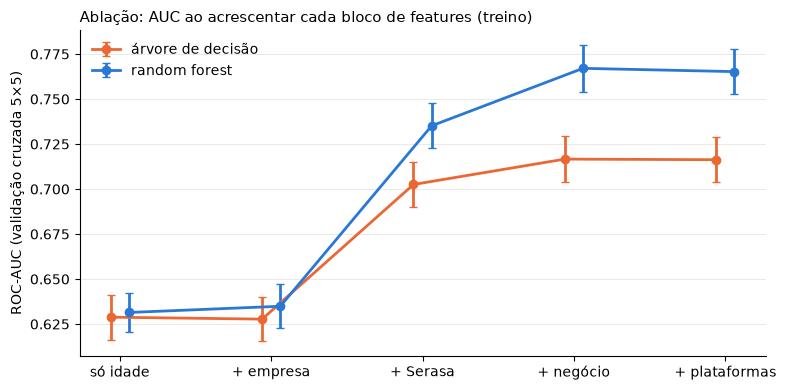

In [18]:
fator = np.sqrt(1 / len(cv) + len(cv[0][1]) / len(cv[0][0]))  # erro padrão corrigido = fator × desvio
fig, ax = plt.subplots(figsize=(8, 4))
for (m, cor), desloc in zip([("árvore de decisão", LARANJA), ("random forest", AZUL)], [-0.06, 0.06]):
    media = [aucs[(p, m)].mean() for p in passos_A]
    erro = [fator * aucs[(p, m)].std(ddof=1) for p in passos_A]
    ax.errorbar(np.arange(len(passos_A)) + desloc, media, yerr=erro, color=cor, marker="o", lw=2, capsize=3, label=m)
ax.set_xticks(range(len(passos_A)), passos_A)
ax.set_ylabel("ROC-AUC (validação cruzada 5×5)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", lw=0.6)
ax.legend(frameon=False)
ax.set_title("Ablação: AUC ao acrescentar cada bloco de features (treino)", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "kan5_ablacao.png", dpi=150); plt.show()

In [19]:
# ganho = AUC com o item − AUC sem o item, pareado nos mesmos folds
testes = [
    ("A", "empresa", "+ empresa", "só idade"),
    ("A", "Serasa", "+ Serasa", "+ empresa"),
    ("A", "negócio", "+ negócio", "+ Serasa"),
    ("A", "plataformas", "+ plataformas", "+ negócio"),
    ("B", "negativações", COMPLETO, "sem negativações"),
    ("B", "nº de credores", COMPLETO, "sem nº de credores"),
    ("C", "tipo de credor", COMPLETO, "sem tipo de credor"),
    ("D", "target encoding no CNAE (vs. raras)", "CNAE com target encoding", COMPLETO),
    ("D", "divisão do CNAE", COMPLETO, "sem divisão do CNAE"),
]
pd.DataFrame([
    {"teste": t, "item": item, "modelo": m, **av.comparar(aucs[(com, m)], aucs[(sem_item, m)], cv)}
    for t, item, com, sem_item in testes for m in modelos
]).set_index(["teste", "item", "modelo"])

ganho  \
teste item                                modelo                     
A     empresa                             árvore de decisão -0.001   
                                          random forest      0.003   
      Serasa                              árvore de decisão  0.075   
                                          random forest      0.100   
      negócio                             árvore de decisão  0.014   
                                          random forest      0.032   
      plataformas                         árvore de decisão -0.000   
                                          random forest     -0.002   
B     negativações                        árvore de decisão -0.000   
                                          random forest     -0.001   
      nº de credores                      árvore de decisão -0.002   
                                          random forest     -0.001   
C     tipo de credor                      árvore de decisão -0.004   
                                          random forest     -0.002   
D     target encoding no CNAE (vs. raras) árvore de decisão -0.004   
                                          random forest     -0.001   
      divisão do CNAE                     árvore de decisão -0.000   
                                          random forest      0.000   

                                                             erro padrão  \
teste item                                modelo                           
A     empresa                             árvore de decisão        0.009   
                                          random forest            0.010   
      Serasa                              árvore de decisão        0.016   
                                          random forest            0.015   
      negócio                             árvore de decisão        0.009   
                                          random forest            0.006   
      plataformas                         árvore de decisão        0.001   
                                          random forest            0.001   
B     negativações                        árvore de decisão        0.001   
                                          random forest            0.001   
      nº de credores                      árvore de decisão        0.005   
                                          random forest            0.002   
C     tipo de credor                      árvore de decisão        0.004   
                                          random forest            0.002   
D     target encoding no CNAE (vs. raras) árvore de decisão        0.006   
                                          random forest            0.003   
      divisão do CNAE                     árvore de decisão        0.001   
                                          random forest            0.001   

                                                             ganho / erro padrão  \
teste item                                modelo                                   
A     empresa                             árvore de decisão               -0.125   
                                          random forest                    0.338   
      Serasa                              árvore de decisão                4.674   
                                          random forest                    6.677   
      negócio                             árvore de decisão                1.657   
                                          random forest                    5.373   
      plataformas                         árvore de decisão               -0.640   
                                          random forest                   -1.309   
B     negativações                        árvore de decisão               -0.239   
                                          random forest                   -1.007   
      nº de credores                      árvore de decisão               -0.348   
                                          rando

**Leitura** (decisões pela Random Forest; a árvore de decisão concorda em todos os testes):

- **Linha de base:** só a idade dá AUC 0,631, perto do 0,639 da EDA.

- **Serasa é o bloco que mais acrescenta:** +0,100 (0,635 → 0,735), ~7 erros padrão. **Negócio vem depois:** +0,032 (→ 0,767), ~5 erros padrão. A árvore de decisão sozinha fica ~0,05 abaixo da Random Forest (0,717).

- **Plataformas (−0,002), negativações (−0,001), tipo de credor (−0,002) e divisão do CNAE (0,000):** não acrescentam. As perdas são minúsculas e só passam de 1 erro padrão em plataformas e negativações porque as diferenças pareadas são muito consistentes: tirá-las não custa nada.
  - Negativações e nº de credores são redundantes, como a EDA indicou (ρ = 0,90). Os credores ficam pela exceção da regra; `sem_registro_serasa` e `negativado_sem_credor` usam as negativações por dentro e continuam.
  - O tipo de credor não acrescenta ao número de credores: com só 534 clientes com credores, quem deve a mais tipos também deve a mais credores. A divisão em tipos continua útil como descrição, no relatório e na política de crédito.

- ***Target encoding* no CNAE (−0,001):** não ganha das raras agrupadas, que ficam como padrão.

- **Empresa (+0,003, neutro):** inconclusivo, porque o bloco foi testado logo depois da idade, antes da Serasa e do negócio. A rodada de confirmação testa a remoção dele no modelo final.

### 6.1 Rodada de confirmação

Duas checagens antes de fechar a lista:
1. **Bloco empresa** (capital social e natureza jurídica): faz falta **no modelo final**, com a Serasa e o negócio já presentes?
2. **Remoções juntas:** cada remoção foi testada sozinha, e várias perdas neutras podem somar. O modelo final não pode ficar pior que o completo.

Modelo final proposto = completo sem plataformas, negativações, tipo de credor (`deve_*`) e divisão do CNAE.

In [20]:
REMOVIDAS = BLOCOS["plataformas"] + ["negativacoes", *DEVE, "cnae_divisao"]
FINAL = "final proposto"
configs_conf = {
    FINAL: (sem(*REMOVIDAS), "raras"),
    "final sem empresa": (sem(*REMOVIDAS, *BLOCOS["empresa"]), "raras"),
}
for nome, (cols, cnae) in configs_conf.items():
    for m, modelo in modelos.items():
        pipe = make_pipeline(fa.montar_preprocessador(cols, cnae), clone(modelo))
        aucs[(nome, m)] = av.auc_por_fold(pipe, X_treino, y_treino, cv)
configs |= configs_conf
print(len(configs[FINAL][0]), "features no modelo final, contra", len(TODAS), "no completo")

pd.DataFrame({k: {"AUC médio": v.mean(), "desvio": v.std(ddof=1)}
              for k, v in aucs.items() if k[0] in [COMPLETO, *configs_conf]}).T.unstack()

13 features no modelo final, contra 23 no completo


AUC médio                          desvio  \
                  random forest árvore de decisão random forest   
+ plataformas             0.765             0.716         0.024   
final proposto            0.766             0.720         0.024   
final sem empresa         0.757             0.721         0.025   

                                     
                  árvore de decisão  
+ plataformas                 0.023  
final proposto                0.025  
final sem empresa             0.021

In [21]:
testes_conf = [
    ("empresa, no modelo final", FINAL, "final sem empresa"),
    ("features removidas, juntas (completo vs. final)", COMPLETO, FINAL),
]
pd.DataFrame([
    {"item": item, "modelo": m, **av.comparar(aucs[(com, m)], aucs[(sem_item, m)], cv)}
    for item, com, sem_item in testes_conf for m in modelos
]).set_index(["item", "modelo"])

ganho  \
item                                            modelo                     
empresa, no modelo final                        árvore de decisão -0.001   
                                                random forest      0.009   
features removidas, juntas (completo vs. final) árvore de decisão -0.004   
                                                random forest     -0.001   

                                                                   erro padrão  \
item                                            modelo                           
empresa, no modelo final                        árvore de decisão        0.006   
                                                random forest            0.006   
features removidas, juntas (completo vs. final) árvore de decisão        0.004   
                                                random forest            0.002   

                                                                   ganho / erro padrão  \
item                                            modelo                                   
empresa, no modelo final                        árvore de decisão               -0.102   
                                                random forest                    1.535   
features removidas, juntas (completo vs. final) árvore de decisão               -0.982   
                                                random forest                   -0.494   

                                                                     veredito  
item                                            modelo                         
empresa, no modelo final                        árvore de decisão      neutro  
                                                random forest      acrescenta  
features removidas, juntas (completo vs. final) árvore de decisão      neutro  
                                                random forest          neutro

**Como ler:**
- **empresa:** "acrescenta" → capital e natureza ficam; "neutro" ou "atrapalha" → saem.
- **removidas, juntas:** precisa dar "neutro" ou "atrapalha" (as removidas não fazem falta). Se der "acrescenta", as remoções somadas custam AUC e precisam ser revistas.

**Leitura:**
- **Empresa fica.** No modelo final, capital social e natureza acrescentam +0,009 de AUC na Random Forest (1,5 erro padrão). No teste A pareciam inúteis porque entraram logo depois da idade; com a Serasa e o negócio presentes, a Random Forest as combina com as outras variáveis. A árvore de profundidade 4 não as usa (−0,001), o que é esperado num modelo tão pequeno.
- **As remoções juntas não custam nada:** o modelo final tem o mesmo AUC do completo (Random Forest 0,766 contra 0,765; árvore 0,720 contra 0,716), com 13 features em vez de 23.

**Lista ao fim da 6.1** (13 features; a 6.2 tira mais duas e chega a 11, e a 6.3 tira `protestos` e fecha nas 10 de `fa.FEATURES_FINAIS`):

| Bloco | Features |
|---|---|
| Idade | `idade_cnpj_ord` |
| Empresa | `capital_social_ord`, `natureza` |
| Serasa | `n_credores`, `tem_credores`, `socio_negativado`, `sem_registro_serasa`, `negativado_sem_credor`, `protestos` |
| Negócio | `fonte_cliente`, `segmento_cliente`, `cnae_classe`, `regiao` |

Saem: plataformas (5), `negativacoes`, `deve_*` (3) e `cnae_divisao`. O CNAE fica com as classes raras agrupadas, sem *target encoding*. `protestos` e `regiao` ficam por estarem em blocos que acrescentam; como a EDA os indica como fracos, a seção 6.3 testa cada uma sozinha.


### 6.2 Dependência da Serasa

A Serasa é o bloco que mais acrescenta (+0,100 de AUC). Isso é esperado num modelo de aplicação, mas traz dois riscos:
- **vazamento pelo tempo:** não sabemos quando a Serasa foi consultada. Se foi depois do calote, e se a própria Praso negativa quem não paga, parte do sinal seria o próprio alvo. Os credores mais ligados ao calote são justamente Distribuição e Alimentos e Bebidas (EDA 4.3), o mesmo tipo de empresa que a Praso. Os dados não permitem verificar isso;
- **modelo fraco para quem não tem histórico:** para os clientes sem nenhum registro na Serasa, o modelo só tem idade, empresa e negócio.

Três checagens no treino, com a Random Forest:
1. **`tem_credores` e `sem_registro_serasa`:** são funções de outras features que a árvore monta sozinha. `tem_credores` é `n_credores > 0`; `sem_registro_serasa` é `n_credores = 0`, sócio sem negativação e `negativado_sem_credor = 0` (todo cliente com credor tem negativação, então a única negativação fora dos credores é a de quem veio sem credor listado). As duas saíram da lista final; aqui confirmamos que as retiradas não custam nada. `sem_registro_serasa` continua sendo usada para separar os grupos do item 3.
2. **Modelo sem a Serasa:** quanto o modelo vale só com idade, empresa e negócio. É o piso, caso a Serasa tenha vazamento ou fique indisponível.
3. **AUC por grupo** (sem registro na Serasa × com registro), também com as plataformas de volta: a ablação mediu as plataformas na base toda, onde a Serasa domina; no grupo sem registro, elas podem ajudar.

Aqui "final" é a lista ao fim da 6.2 (11 features, ainda com `protestos`, que sai na 6.3).


In [22]:
# Lista ao fim da 6.2: a da 6.1 sem tem_credores e sem_registro_serasa. Ainda tem protestos, que sai na 6.3.
LISTA_62 = fa.FEATURES_FINAIS + ["protestos"]
assert set(LISTA_62) == set(configs[FINAL][0]) - {"tem_credores", "sem_registro_serasa"}
SERASA_FINAL = [c for c in LISTA_62 if c in BLOCOS["Serasa"]]
grupo_serasa = X_treino["sem_registro_serasa"].map({1: "sem registro", 0: "com registro"})
display(pd.DataFrame({
    "clientes no treino": grupo_serasa.value_counts(),
    "taxa de inadimplência": y_treino.groupby(grupo_serasa).mean(),
}))

configs_62 = {
    "final": LISTA_62,
    "final + sem_registro_serasa": LISTA_62 + ["sem_registro_serasa"],
    "final sem Serasa": [c for c in LISTA_62 if c not in SERASA_FINAL],
    "final + plataformas": LISTA_62 + BLOCOS["plataformas"],
}
por_grupo, inicio = {}, time.time()
for nome, cols in configs_62.items():
    pipe = make_pipeline(fa.montar_preprocessador(cols), clone(modelos["random forest"]))
    por_grupo[nome] = av.auc_por_fold_e_grupo(pipe, X_treino, y_treino, cv, grupo_serasa)
    print(f"{nome:<22} {time.time() - inicio:5.0f}s")
print("Serasa na lista da 6.2:", SERASA_FINAL)

# AUC médio por configuração, na validação inteira e dentro de cada grupo
pd.DataFrame({nome: g.mean() for nome, g in por_grupo.items()}).T[["todos", "sem registro", "com registro"]]

,clientes no treino,taxa de inadimplência
sem_registro_serasa,,
com registro,1282,0.404
sem registro,1118,0.209


final                      8s


final + sem_registro_serasa    16s


final sem Serasa          24s


final + plataformas       32s
Serasa na lista da 6.2: ['n_credores', 'socio_negativado', 'negativado_sem_credor', 'protestos']


,todos,sem registro,com registro
final,0.771,0.767,0.726
final + sem_registro_serasa,0.768,0.769,0.723
final sem Serasa,0.699,0.754,0.676
final + plataformas,0.772,0.768,0.726


In [23]:
rf = "random forest"
comparacoes = [
    ("tem_credores (final da 6.1 vs. final + sem_registro_serasa)", aucs[(FINAL, rf)],
     por_grupo["final + sem_registro_serasa"]["todos"], "todos"),
    ("sem_registro_serasa", por_grupo["final + sem_registro_serasa"]["todos"], por_grupo["final"]["todos"], "todos"),
    *[("Serasa", por_grupo["final"][g], por_grupo["final sem Serasa"][g], g) for g in ["todos", "sem registro", "com registro"]],
    *[("plataformas", por_grupo["final + plataformas"][g], por_grupo["final"][g], g) for g in ["todos", "sem registro", "com registro"]],
]
pd.DataFrame([
    {"item": item, "avaliado em": g, **av.comparar(com, sem_item, cv)} for item, com, sem_item, g in comparacoes
]).set_index(["item", "avaliado em"])

ganho  \
item                                               avaliado em           
tem_credores (final da 6.1 vs. final + sem_regi... todos        -0.002   
sem_registro_serasa                                todos        -0.003   
Serasa                                             todos         0.073   
                                                   sem registro  0.013   
                                                   com registro  0.050   
plataformas                                        todos         0.001   
                                                   sem registro  0.001   
                                                   com registro -0.000   

                                                                 erro padrão  \
item                                               avaliado em                 
tem_credores (final da 6.1 vs. final + sem_regi... todos               0.002   
sem_registro_serasa                                todos               0.002   
Serasa                                             todos               0.011   
                                                   sem registro        0.007   
                                                   com registro        0.013   
plataformas                                        todos               0.001   
                                                   sem registro        0.003   
                                                   com registro        0.002   

                                                                 ganho / erro padrão  \
item                                               avaliado em                         
tem_credores (final da 6.1 vs. final + sem_regi... todos                      -0.717   
sem_registro_serasa                                todos                      -1.484   
Serasa                                             todos                       6.400   
                                                   sem registro                1.730   
                                                   com registro                4.009   
plataformas                                        todos                       0.454   
                                                   sem registro                0.546   
                                                   com registro               -0.124   

                                                                   veredito  
item                                               avaliado em               
tem_credores (final da 6.1 vs. final + sem_regi... todos             neutro  
sem_registro_serasa                                todos          atrapalha  
Serasa                                             todos         acrescenta  
                                                   sem registro  acrescenta  
                                                   com registro  acrescenta  
plataformas                                        todos             neutro  
                                                   sem registro      neutro  
                                                   com registro      neutro

**Como ler as duas tabelas**
- **Grupos:** "sem registro" são os clientes com 0 negativações, 0 credores e sócio limpo (1.118 no treino, 20,9% de inadimplência). "Com registro" é o resto (1.282, 40,4%), e "todos" são os dois juntos.
- A primeira tabela dá o AUC de cada configuração em cada grupo. A segunda dá o ganho de cada item (com × sem) e o veredito.

**Leitura**
1. **Tirar `tem_credores` e `sem_registro_serasa` não custa nada.** As duas retiradas dão "neutro" ou "atrapalha" (−0,002 e −0,003). A lista com 11 features tem AUC 0,771, praticamente igual ao da versão com 13 (0,766).
2. **Para quem não tem registro na Serasa, o modelo funciona quase igual:** AUC 0,767, contra 0,771 em todos. Nesse grupo as features da Serasa são quase todas zero, então quem ordena os clientes é idade, empresa e negócio. A Serasa acrescenta só +0,013 ali.
3. **A Serasa ajuda em duas coisas:** separar os dois grupos (40,4% contra 20,9% de inadimplência) e ordenar quem tem registro (+0,050). No total, acrescenta +0,073.
4. **Sem a Serasa, o AUC cai para 0,699**, ainda bem acima da idade sozinha (0,631). Esse é o piso se a Serasa tiver vazamento pelo tempo ou ficar indisponível.
5. **As plataformas continuam neutras**, inclusive no grupo sem registro, onde mais poderiam ajudar. Ficam de fora.
6. **Por que o grupo "com registro" tem AUC menor (0,726):** dentro de um grupo só, o modelo perde a separação "tem registro × não tem", que é a parte fácil. Isso não quer dizer que ele erra mais nesses clientes.

### 6.3 Verificações finais

Três dúvidas que ficaram abertas, testadas na lista da 6.2 (11 features), com a mesma regra de decisão e os dois modelos:

1. **Marcos de idade.** A EDA (4.1) mostrou degraus por volta de 1.600 dias (a taxa sai da faixa de 30% a 48% e fica perto de 25%) e de 5.000 dias (cai para 11% e depois 6%). Flags `idade > 1.600` e `idade > 5.000` acrescentam algo à posição da faixa? Os dois marcos coincidem com fronteiras de faixa (códigos 13 e 18), e as flags são calculadas linha a linha, sem olhar o alvo.
2. **`protestos`:** entrou por estar no bloco Serasa, que acrescenta, mas a EDA o indica como fraco. Faz falta sozinho?
3. **`regiao`:** o mesmo caso, no bloco negócio.

A seção termina com o AUC dos dois modelos na lista final, depois dessas decisões.


In [24]:
from sklearn.compose import ColumnTransformer

F = LISTA_62  # 11 features, da 6.2
MARCOS = {"idade_mais_1600": 13, "idade_mais_5000": 18}  # código da primeira faixa acima de cada marco
faixas = clientes["idade_cnpj"].cat.categories.astype(str)
assert faixas[13] == "(1600, 2000]" and faixas[18] == "(5000, 8000]"
X_marcos = X_treino.assign(**{nome: (X_treino["idade_cnpj_ord"] >= cod).astype(int) for nome, cod in MARCOS.items()})


def com_marcos(cols):
    """Pré-processador da seção 5 mais as flags de marco de idade, que passam como estão."""
    return ColumnTransformer([("base", fa.montar_preprocessador(cols), cols), ("marcos", "passthrough", list(MARCOS))],
                             verbose_feature_names_out=False).set_output(transform="pandas")


sem_f = lambda *cols: [c for c in F if c not in cols]
configs_63 = {
    "final": fa.montar_preprocessador(F),
    "final + marcos de idade": com_marcos(F),
    "final sem protestos": fa.montar_preprocessador(sem_f("protestos")),
    "final sem regiao": fa.montar_preprocessador(sem_f("regiao")),
}
aucs_63 = {}
for nome, pre_63 in configs_63.items():
    for m, modelo in modelos.items():
        aucs_63[(nome, m)] = av.auc_por_fold(make_pipeline(clone(pre_63), clone(modelo)), X_marcos, y_treino, cv)

pd.DataFrame({k: {"AUC médio": v.mean(), "desvio": v.std(ddof=1)} for k, v in aucs_63.items()}).T.unstack().reindex(list(configs_63))


AUC médio                          desvio  \
                        random forest árvore de decisão random forest   
final                           0.771             0.723         0.025   
final + marcos de idade         0.769             0.723         0.024   
final sem protestos             0.772             0.723         0.024   
final sem regiao                0.769             0.723         0.024   

                                           
                        árvore de decisão  
final                               0.026  
final + marcos de idade             0.026  
final sem protestos                 0.026  
final sem regiao                    0.026

In [25]:
testes_63 = [
    ("marcos de idade", "final + marcos de idade", "final"),
    ("protestos", "final", "final sem protestos"),
    ("regiao", "final", "final sem regiao"),
]
pd.DataFrame([
    {"item": item, "modelo": m, **av.comparar(aucs_63[(com, m)], aucs_63[(sem_item, m)], cv)}
    for item, com, sem_item in testes_63 for m in modelos
]).set_index(["item", "modelo"])


ganho  erro padrão  ganho / erro padrão  \
item            modelo                                                       
marcos de idade árvore de decisão -0.000        0.000               -0.351   
                random forest     -0.002        0.003               -0.757   
protestos       árvore de decisão  0.000        0.000                0.000   
                random forest     -0.001        0.001               -1.001   
regiao          árvore de decisão  0.000        0.000                0.371   
                random forest      0.002        0.002                1.061   

                                     veredito  
item            modelo                         
marcos de idade árvore de decisão      neutro  
                random forest          neutro  
protestos       árvore de decisão      neutro  
                random forest       atrapalha  
regiao          árvore de decisão      neutro  
                random forest      acrescenta

**Leitura** (decisões pela Random Forest, como na seção 6):

1. **Marcos de idade não acrescentam** (−0,002, neutro). A posição da faixa já contém os dois degraus: a floresta corta a idade nos pontos que quiser, e a árvore de decisão nem chega a usar as flags (mesmo AUC em todos os folds). Ficam de fora.
2. **`regiao` fica:** retirá-la custa 0,002 de AUC (1,06 erro padrão, "acrescenta").
3. **`protestos` sai:** retirá-la sobe o AUC da Random Forest em 0,001 (0,771 → 0,772), 1,0 erro padrão, o que pela regra é "atrapalha". A árvore de decisão não vê diferença (0,723 com e sem), porque com profundidade 4 não chega a usá-la. Faz sentido com a EDA: 92% dos clientes não têm protestos, e o que eles indicam já está nas outras features da Serasa (credores e sócio negativado).
4. **Árvore de decisão: 0,723** com as 11 da 6.2 e com as 10 finais, contra 0,720 com as 13 da 6.1. A Random Forest fica ~0,05 acima.

**Lista final** (`fa.FEATURES_FINAIS`, 10 features): a da 6.2 sem `protestos`. A célula abaixo confere a lista e mostra o AUC final.


In [26]:
# Lista final = lista da 6.2 sem protestos; o AUC é o da configuração "final sem protestos"
assert set(fa.FEATURES_FINAIS) == set(sem_f("protestos")) and len(fa.FEATURES_FINAIS) == 10
print("features finais:", ", ".join(fa.FEATURES_FINAIS))
pd.DataFrame({m: {"AUC médio": aucs_63[("final sem protestos", m)].mean(),
                  "desvio": aucs_63[("final sem protestos", m)].std(ddof=1)} for m in modelos}).T


features finais: idade_cnpj_ord, capital_social_ord, natureza, n_credores, socio_negativado, negativado_sem_credor, fonte_cliente, segmento_cliente, cnae_classe, regiao


,AUC médio,desvio
árvore de decisão,0.723,0.026
random forest,0.772,0.024


## 7. Checagens de vazamento

Conferências automáticas de que nada do teste, do alvo ou dos pedidos entrou nas features ou nas escolhas. Cada linha da tabela é um `assert`: se alguma falhar, a célula para com erro.

In [27]:
teste_ids = set(clientes.loc[conjunto == "teste", "id_cliente"])
treino_ids = set(clientes.loc[conjunto == "treino", "id_cliente"])
amostra = clientes.sample(200, random_state=0)

checagens = {
    "nenhuma coluna dos pedidos nas features": not set(X.columns) & (set(pedidos.columns) - {"id_cliente"}),
    "nem id_cliente, nem alvo, nem 'tem pedidos' nas features": not set(X.columns) & {"id_cliente", "inadimplente", "tem_pedidos"},
    "criar_features é linha a linha (não depende do resto da base)": fa.criar_features(amostra).equals(X.loc[amostra.index]),
    "features finais estão na saída de criar_features": set(fa.FEATURES_FINAIS) <= set(X.columns),
    "treino e teste não se sobrepõem e cobrem a base": not treino_ids & teste_ids and len(treino_ids | teste_ids) == len(clientes),
    "split salvo = split recriado pela seed": sp.carregar_split().equals(sp.criar_split(clientes, pedidos)),
    "ablação usou só o treino (X e y)": X_treino.index.equals(y_treino.index)
        and set(clientes.loc[X_treino.index, "id_cliente"]) == treino_ids,
    "folds da validação cruzada só têm posições do treino": all(max(t.max(), v.max()) < len(X_treino) for t, v in cv),
}
for nome, ok in checagens.items():
    assert ok, nome
pd.Series(checagens, name="ok").to_frame()

,ok
nenhuma coluna dos pedidos nas features,True
"nem id_cliente, nem alvo, nem 'tem pedidos' nas features",True
criar_features é linha a linha (não depende do resto da base),True
features finais estão na saída de criar_features,True
treino e teste não se sobrepõem e cobrem a base,True
split salvo = split recriado pela seed,True
ablação usou só o treino (X e y),True
folds da validação cruzada só têm posições do treino,True


In [28]:
# O pré-processador final, ajustado no treino, transforma o teste sem erro e com as mesmas colunas.
# Só confere o formato: o alvo do teste não é lido.
pre_final = fa.montar_preprocessador(fa.FEATURES_FINAIS).fit(X_treino, y_treino)
Z_treino, Z_teste = pre_final.transform(X_treino), pre_final.transform(X[conjunto == "teste"])
assert list(Z_treino.columns) == list(Z_teste.columns) and Z_teste.notna().all().all()
print("colunas após o pré-processador:", Z_treino.shape[1], "| linhas no teste:", len(Z_teste))

colunas após o pré-processador: 10 | linhas no teste: 600


## 8. Resumo

**Dados e split**
- 3.000 clientes, 31,3% de inadimplência. Só a tabela de clientes entra nas features; os pedidos só servem para estratificar o split.
- **Split 80/20** (`src/split.py`, seed 42), estratificado por `inadimplente × tem_pedidos`: treino com 2.400 clientes e teste com 600, os dois com 31,3% de inadimplência e 22% com pedidos. No treino, **validação cruzada estratificada repetida, 5 folds × 5 repetições** (`sp.folds`). O teste fica intocado para a avaliação final.
- No teste, só 28 inadimplentes têm pedidos: a comparação com o modelo comportamental (KAN-8) precisa de intervalo de confiança.

**Decisões de qualidade**
- `google_maps_tem_website` é cópia de `tem_gmaps` (nulo exatamente em quem não está no Maps) e saiu.
- `n_credores` conta os itens da lista de credores, com repetição de segmento (dois credores do mesmo setor).
- `sem_registro_serasa` exige os três sinais limpos: 0 negativações, 0 credores e sócio sem negativação. Ela saiu do modelo, porque a árvore a monta a partir de `n_credores`, `socio_negativado` e `negativado_sem_credor`, mas define os grupos da análise de dependência da Serasa (6.2).
- Os 30 segmentos de credor foram classificados pelo significado em mercadoria, financeiro e serviços (Diversos e Governo ficam sem tipo). A divisão não entrou no modelo final (ablação), mas descreve os credores no relatório.

**Pré-processador** (`fa.montar_preprocessador`, ajustado só no treino, dentro do `Pipeline`)
- Categorias com menos de 30 clientes no treino viram um grupo só. Na classe do CNAE, só 8 das 103 classes do treino ficam com código próprio.
- Uma versão só, para modelos de árvore: numéricas e binárias passam como estão, categóricas viram códigos.

**Modelos:** árvore de decisão e Random Forest. O risco vem da combinação das features (a idade muda o peso do sócio negativado; 2 ou mais credores anulam a proteção da idade; EDA 6), e árvores montam essas combinações e os degraus da idade sozinhas.

**Ablação** (seção 6, Random Forest com parâmetros fixos, validação cruzada 5×5 no treino)

| Configuração | AUC Random Forest | AUC árvore de decisão |
|---|---|---|
| só idade (linha de base) | 0,631 | 0,629 |
| + Serasa | 0,735 | 0,703 |
| + negócio | 0,767 | 0,717 |
| completo (23 features) | 0,765 | 0,716 |
| final da 6.1 (13 features, com `tem_credores` e `sem_registro_serasa`) | 0,766 | 0,720 |
| final da 6.2 (11 features) | 0,771 | 0,723 |
| **final (10 features, sem `protestos`; 6.3)** | **0,772** | **0,723** |

A Serasa (+0,100) e o tipo de negócio (+0,032) são o que mais acrescenta à idade. Plataformas, negativações, tipo de credor e divisão do CNAE saíram sem perda. Capital social e natureza jurídica ficam: acrescentam +0,009 no modelo final. `tem_credores` e `sem_registro_serasa` saíram por serem funções de outras features (6.2), e o AUC subiu para 0,771. Por último, `protestos` saiu na verificação final (6.3), e o modelo final, com 10 features, chega a 0,772.

**Verificações finais** (6.3): flags de marco de idade (> 1.600 e > 5.000 dias) não acrescentam, porque a faixa já contém os degraus. `regiao` acrescenta (+0,002) e fica. `protestos` saiu: sem ela, o AUC da Random Forest sobe 0,001 (1 erro padrão, "atrapalha"), e a árvore de decisão não a usa.

**Dependência da Serasa** (6.2, medida com as 11 features da 6.2, ainda com `protestos`): a Serasa acrescenta +0,073 de AUC, mas o modelo não depende dela para ordenar quem não tem histórico: nos clientes sem nenhum registro, o AUC é 0,767 (contra 0,771 no geral), e a Serasa acrescenta só +0,013 ali. Sem a Serasa, o modelo cai para 0,699, ainda bem acima da idade sozinha (0,631).

**Features finais** (`fa.FEATURES_FINAIS`, 10)

| Feature | Origem | Por quê |
|---|---|---|
| `idade_cnpj_ord` | idade do CNPJ (faixa) | variável mais forte: de 57% a 6% de inadimplência (EDA 4.1) |
| `capital_social_ord`, `natureza` | cadastro | acrescentam no modelo final (6.1) |
| `n_credores` | `serasa_credores` | gradiente de 28% a 72% (EDA 4.3); `tem_credores` saiu por ser só `n_credores > 0` (6.2) |
| `socio_negativado` | Serasa | 42% contra 22% (EDA 4.3) |
| `negativado_sem_credor` | Serasa | os 97 casos em que o credor pode estar faltando |
| `fonte_cliente`, `segmento_cliente` | cadastro | efeito próprio, além da idade (EDA 6.3) |
| `cnae_classe` | CNAE (classe) | classes raras agrupadas |
| `regiao` | município | Fortaleza / metropolitana / interior; acrescenta +0,002 (6.3) |

**Para a KAN-6 (modelo de aplicação)**
- `fa.criar_features(clientes)` → `fa.montar_preprocessador(fa.FEATURES_FINAIS)` → modelo, tudo num `Pipeline`.
- Split com `sp.carregar_split()`, folds com `sp.folds(treino, pedidos)` e comparações com `src/avaliacao.py` (erro padrão corrigido de Nadeau e Bengio).
- Linhas de base a superar, na validação cruzada, com as 10 features finais: **0,631** (só a idade) e **0,723** (árvore de decisão de profundidade 4). Random Forest sem tuning: **0,772**.
